# 05 Temporal heterogeneous graph construction
Node types: account, device, ip. Edge types: pays, uses (device), from (ip), each with reverse edges. A snapshot at cutoff *c* contains only edges strictly before *c*; a payment in [c, c+4 days) is scored with that snapshot, so it never sees itself or the future.

In [1]:
import sys, pathlib, json, warnings; warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
def table(name):
    p = ROOT / 'reports' / 'tables' / name
    return pd.read_csv(p) if p.exists() else None

In [2]:
from presage.simulation.app_world import simulate, SimConfig
from presage.graph.snapshots import build_snapshots
df, acc = simulate(SimConfig(n_customers=800, n_payees=1500, days=60, n_mule_networks=20, scam_rate_per_day=2.0, recurring_windows=((10, 20),), sudden_drift_day=45))
snaps, snap_of = build_snapshots(df, acc, step_days=4.0)
print(pd.DataFrame([dict(k=s.k, day=s.cutoff/86400, pay_edges=s.pay_ei.shape[1], device_edges=s.dev_ei.shape[1], ip_edges=s.ip_ei.shape[1]) for s in snaps]).iloc[::3])

18:45:26 INFO sim: simulated 41038 txns (222 scam payments = 0.541%), 2515 accounts, 215 mule accounts


18:45:26 INFO snapshots: built 16 snapshots (2515 accounts, 3002 devices, 1600 ips)


     k   day  pay_edges  device_edges  ip_edges
0    0   0.0          0             0         0
3    3  12.0       5188          1727      2995
6    6  24.0       8617          2253      5739
9    9  36.0      11455          2597      8229
12  12  48.0      13880          2855     10502
15  15  60.0      16547          3147     13359


### Strictness check
The edge-recency attribute is `log1p(days between cutoff and the edge's last payment)`, so it must be >= 0 for every edge.

In [3]:
print('min recency attr across snapshots:', min(float(s.pay_ea[:,2].min()) for s in snaps if s.pay_ea.shape[0]))

min recency attr across snapshots: 0.00017095891234930605


### Graph-derived features (PageRank, clustering, components, betweenness, confirmed-mule neighbours, ...)

In [4]:
from presage.features.network import build_network_features
N = build_network_features(df, acc, step_days=4.0); print(N.shape); N.describe().T[['mean','50%','max']].head(14).round(3)

18:45:28 INFO netfeat: built 30 network features (16 snapshots, step 4.0d)


(41038, 31)


,mean,50%,max
txn_id,20518.500,20518.500,41037.000
dg_in_deg,70.819,10.000,644.000
dg_out_deg,2.094,0.000,542.000
dg_w_in,17628.553,1719.265,244013.656
dg_w_out,324.068,0.000,86577.781
dg_pr,9.285,1.656,72.908
dg_pr_delta,0.732,-0.007,42.530
dg_clus,0.018,0.003,1.000
dg_comp,2009.613,2291.000,2436.000
dg_btw,18.564,0.432,209.747


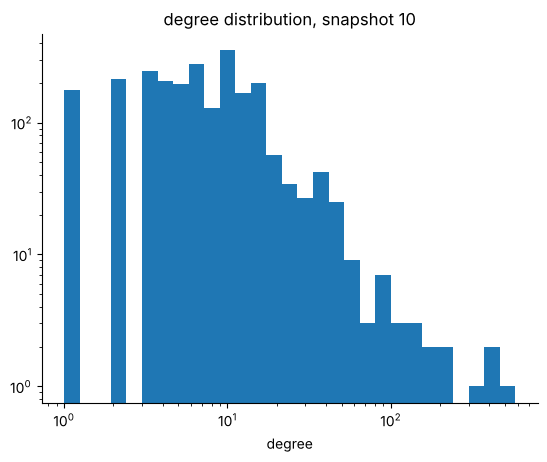

In [5]:
import networkx as nx
s = snaps[10]; G = nx.Graph(); G.add_edges_from(s.pay_ei.T.tolist())
deg = np.array([d for _, d in G.degree()]); plt.hist(deg, bins=np.logspace(0, np.log10(deg.max()+1), 30)); plt.xscale('log'); plt.yscale('log'); plt.title('degree distribution, snapshot 10'); plt.xlabel('degree');

Label-derived node features (neighbouring *confirmed* mules) are built only from reports that have already arrived by the cutoff (payment time + report delay), so label delay is respected.